In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Urządzenie: {device}")

Urządzenie: cpu


In [11]:
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False)

In [12]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()

        def block(cin, cout):
            layers = [
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU()
            ]
            if pool == "max":
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(kernel_size=2, stride=2))
            elif pool == "stride":
                layers += [
                    nn.Conv2d(cout, cout, kernel_size=3, stride=2, padding=1),
                    nn.BatchNorm2d(cout),
                    nn.ReLU()
                ]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            block(1, 32),
            block(32, 64)
        )

        # Wyznaczenie rozmiaru mapy cech przed głowicą klasyfikującą
        with torch.no_grad():
            dummy = torch.zeros(1, 1, 28, 28)
            feat_out = self.features(dummy)
            self.fmap_shape = tuple(feat_out.shape[1:])  # (C, H, W)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(self.fmap_shape[0], n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))

In [13]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total

def train_model(model, epochs=6, lr=1e-3):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    accs = []
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
        acc = evaluate(model, test_dl)
        accs.append(acc)
    return accs

In [14]:
variants = ["max", "avg", "stride"]
results = {}

for p in variants:
    torch.manual_seed(0)  # Reset ziarna losowości dla uczciwego porównania
    m = CNN(pool=p)
    accs = train_model(m, epochs=6)
    results[p] = {
        "accs": accs,
        "best_acc": max(accs) * 100,
        "params": count_params(m),
        "fmap": m.fmap_shape
    }
    print(f"Wariant: {p:6} | Mapa cech: {str(m.fmap_shape):10} | Parametry: {count_params(m):>6,} | Best Acc: {max(accs)*100:.2f}%")

Wariant: max    | Mapa cech: (64, 7, 7) | Parametry: 19,658 | Best Acc: 81.24%
Wariant: avg    | Mapa cech: (64, 7, 7) | Parametry: 19,658 | Best Acc: 80.23%
Wariant: stride | Mapa cech: (64, 7, 7) | Parametry: 66,026 | Best Acc: 89.14%


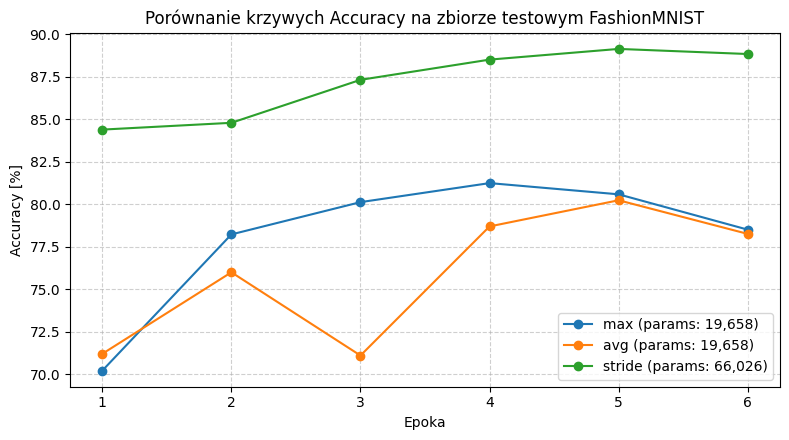

In [15]:
plt.figure(figsize=(8, 4.5))
for p in variants:
    plt.plot(
        range(1, 7),
        [a * 100 for a in results[p]["accs"]],
        marker="o",
        label=f"{p} (params: {results[p]['params']:,})"
    )

plt.title("Porównanie krzywych Accuracy na zbiorze testowym FashionMNIST")
plt.xlabel("Epoka")
plt.ylabel("Accuracy [%]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("krzywe_accuracy.png", dpi=150)
plt.show()